In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import matplotlib.ticker as ticker
import seaborn as sns
from sklearn.metrics import roc_curve, auc

# Mounting the Google Drive, the file path might be different for each of us
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Load results excel
models = pd.read_excel('/content/drive/My Drive/MSBA/MSBA BA Project/All_models_stats.xlsx')
models

,Model,Precision,Recall,F1 Score,Specificity,Netprofit,Cutoff
0,Small Class Tree,0.338420,0.808831,0.477184,0.546832,1.186555e+09,0.50
1,Bagging Tree,0.346693,0.823573,0.487969,0.555214,1.169843e+09,0.48
2,Boosting Tree,0.366538,0.672813,0.474549,0.666748,1.513241e+09,0.50
3,Random Forest Tree,0.357343,0.556040,0.435079,0.713400,1.689173e+09,0.43
4,KNN,0.461046,0.298746,0.362562,0.899911,1.214843e+09,0.15
5,Logistics stats smf.glm,0.000000,0.000000,0.000000,1.000000,9.781180e+08,0.24
6,Logistics stats sm.GLM,0.000000,0.000000,0.000000,1.000000,9.781180e+08,0.24
7,Logistic Regression Ridge model1,0.291074,0.733250,0.416724,0.488171,7.890429e+08,0.01
8,Logistic Regression Ridge model2,0.221686,0.684829,0.334947,0.310911,9.342260e+08,0.01
9,Logistic Regression Ridge model3,0.300942,0.928566,0.454563,0.381812,9.352135e+08,0.01


In [3]:
models.describe()

,Precision,Recall,F1 Score,Specificity,Netprofit,Cutoff
count,15.000000,15.000000,15.000000,15.000000,1.500000e+01,15.000000
mean,0.233583,0.436704,0.272843,0.727142,9.523887e+08,0.240000
std,0.184575,0.383075,0.212038,0.267062,4.151338e+08,0.210374
min,0.000000,0.000000,0.000000,0.310911,-3.758475e+05,0.010000
25%,0.000000,0.000000,0.000000,0.517502,8.616344e+08,0.010000
50%,0.297302,0.556040,0.362562,0.713400,9.756791e+08,0.240000
75%,0.352018,0.771041,0.452006,1.000000,1.178199e+09,0.455000
max,0.522695,0.928566,0.487969,1.000000,1.689173e+09,0.580000


In [4]:
models.columns

Index(['Model', 'Precision', 'Recall', 'F1 Score', 'Specificity', 'Netprofit',
       'Cutoff'],
      dtype='object')

# Model Performance Comparison

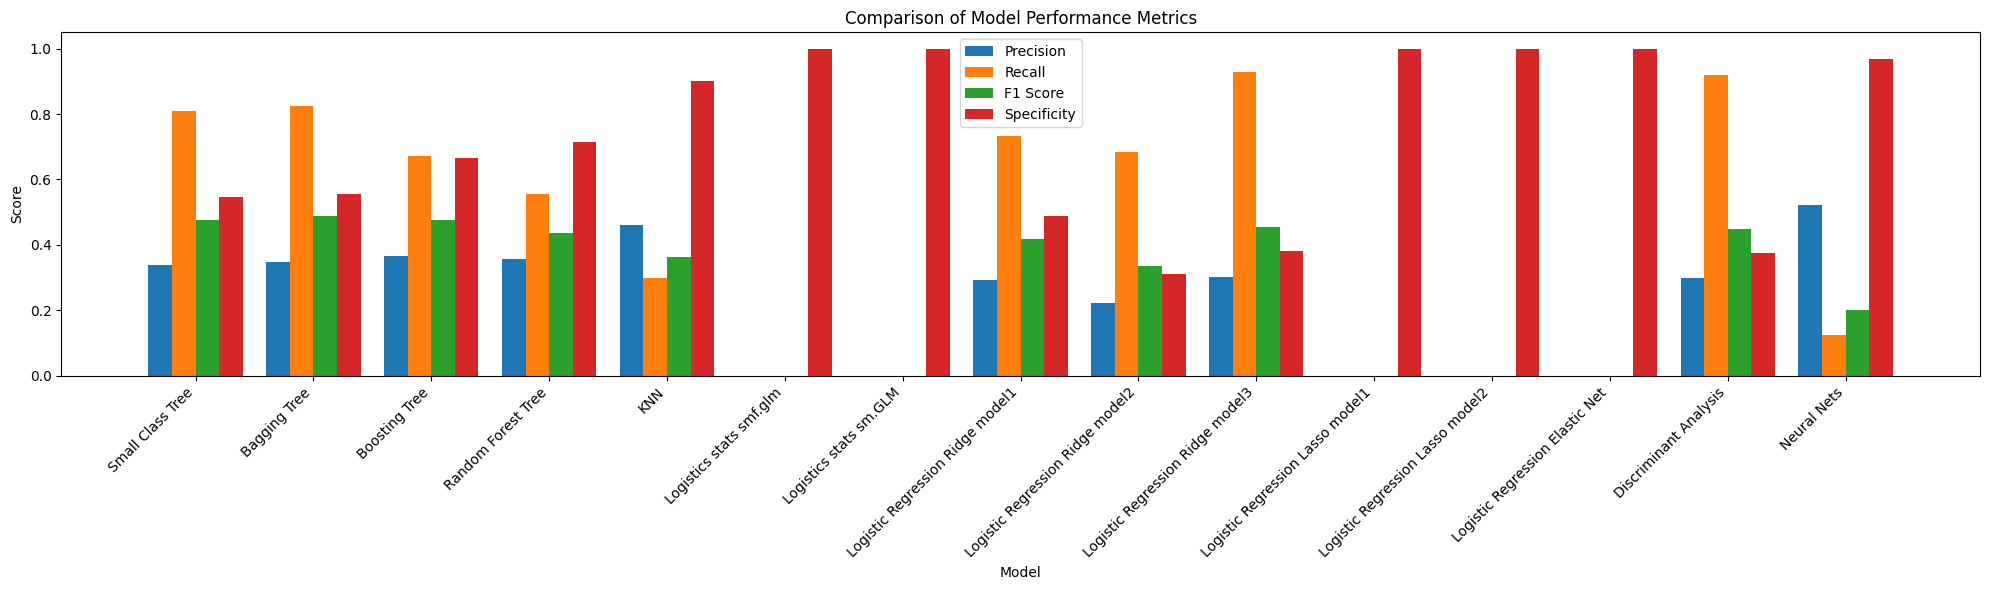

In [5]:
# Select metrics for comparison
metrics = ['Precision', 'Recall', 'F1 Score', 'Specificity']
x = np.arange(len(models['Model']))  # the label locations
width = 0.2  # the width of the bars

fig, ax = plt.subplots(figsize=(20, 6))

# Plot each metric as a separate bar group
for i, metric in enumerate(metrics):
    ax.bar(x + i * width, models[metric], width, label=metric)

# Add labels, title, and legend
ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Comparison of Model Performance Metrics')
ax.set_xticks(x + width * (len(metrics) - 1) / 2)
ax.set_xticklabels(models['Model'], rotation=45, ha='right')
ax.legend()

plt.tight_layout()
plt.show()

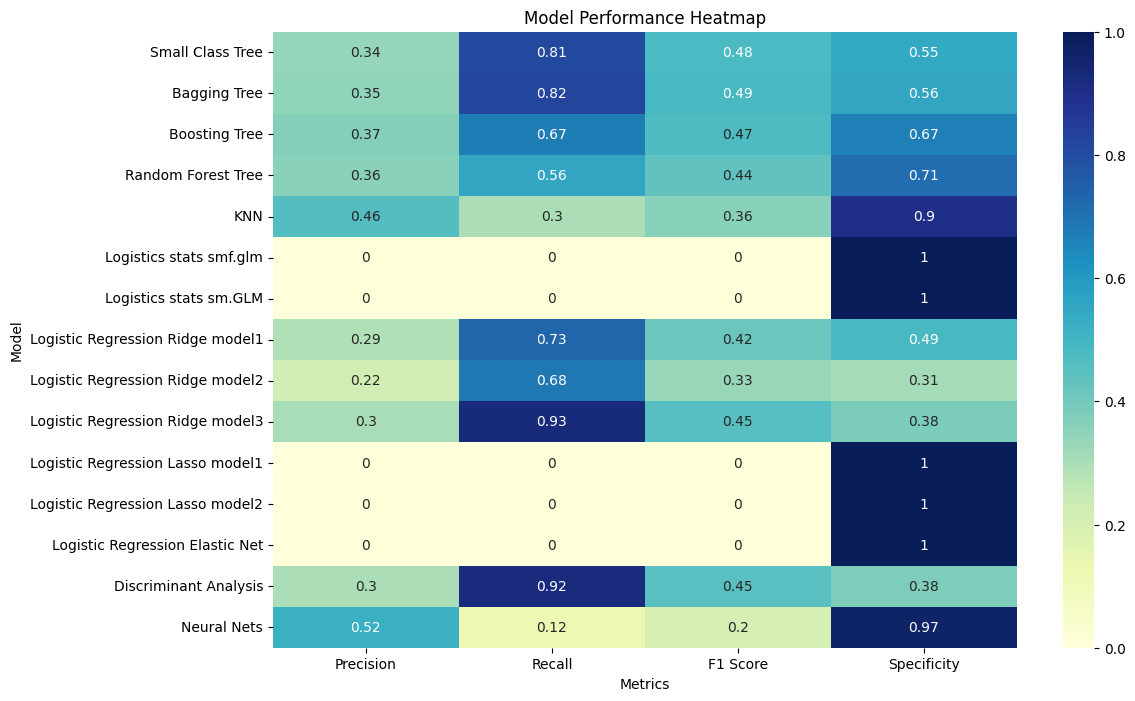

In [6]:
# Heatmap for metrics
heatmap_data = models[metrics].set_index(models['Model'])

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, cmap='YlGnBu', cbar=True)
plt.title('Model Performance Heatmap')
plt.xlabel('Metrics')
plt.ylabel('Model')
plt.show()

# Net Profit Comparison

<ipython-input-66-76ee229f898a>:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(models['Model'], rotation=45, ha='right')


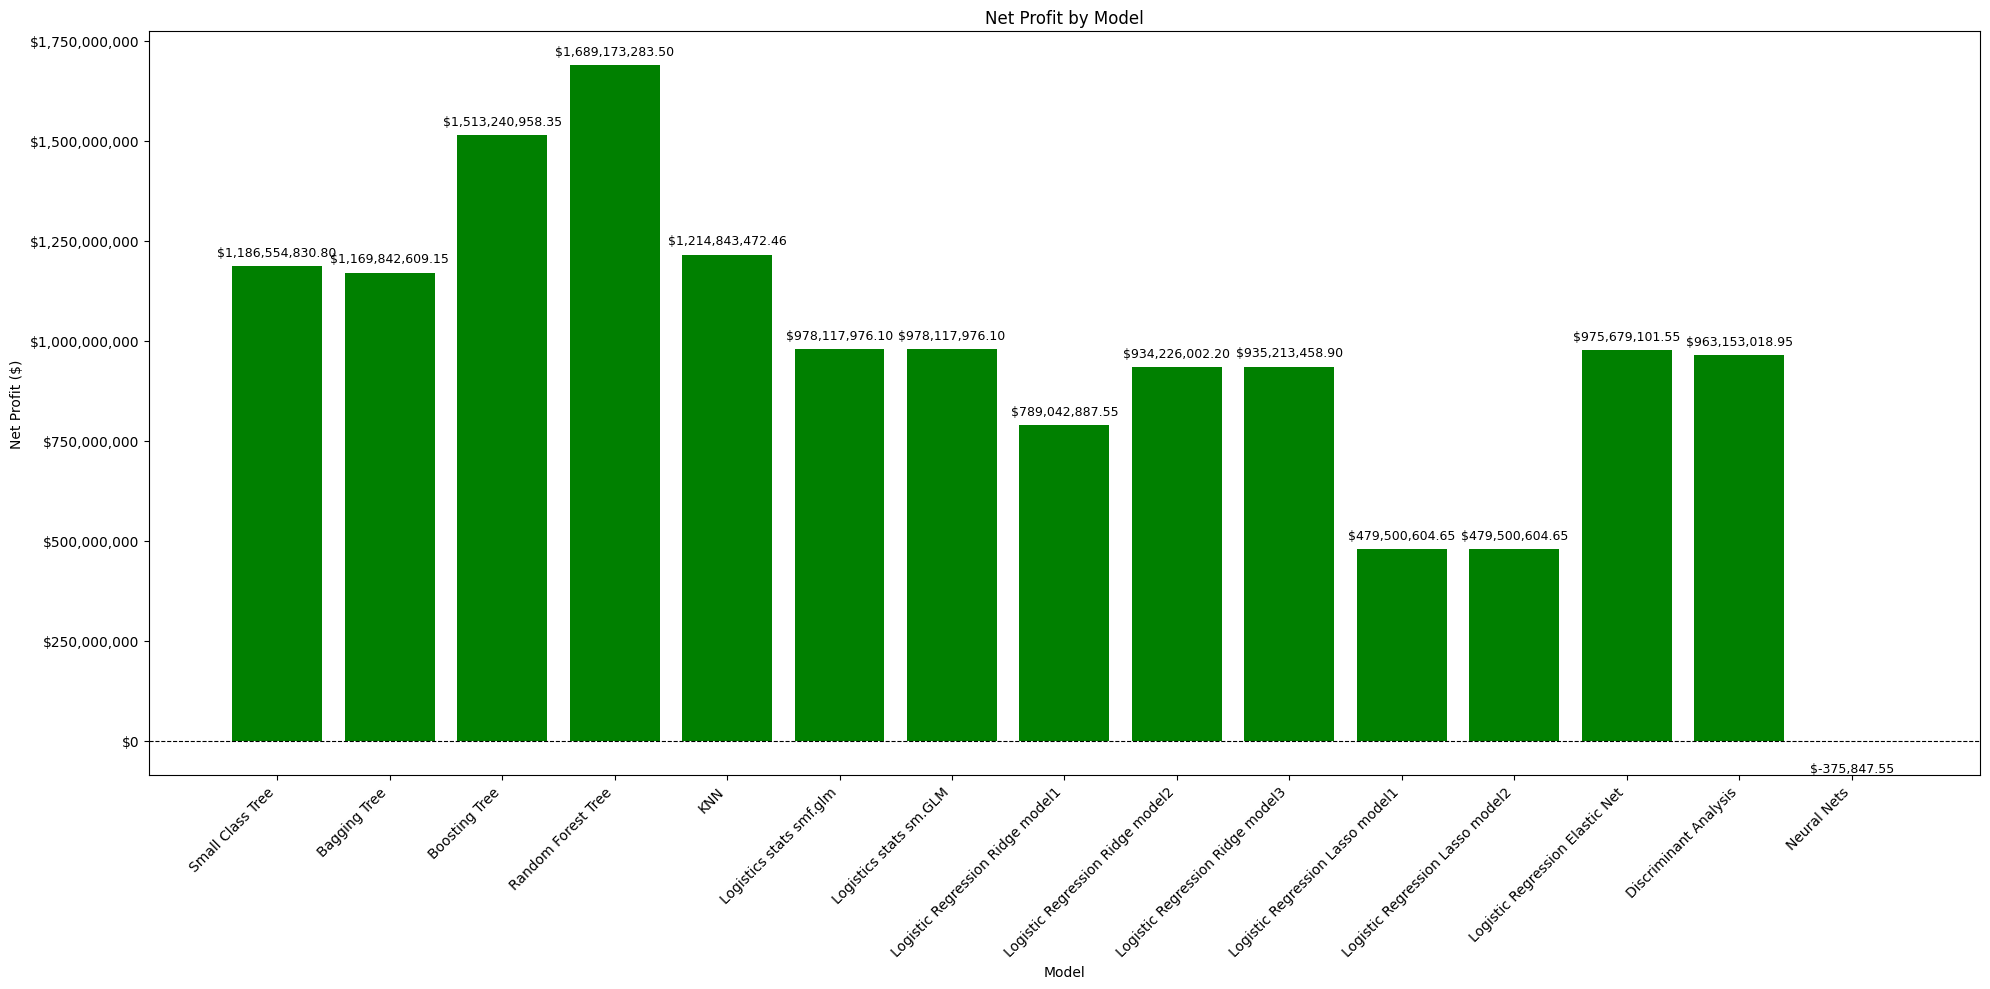

In [ ]:
# Create the bar chart
fig, ax = plt.subplots(figsize=(20, 10))

# Color-code based on positive/negative values
models['Netprofit'] = pd.to_numeric(models['Netprofit'])
colors = ['red' if val < 0 else 'green' for val in models['Netprofit']]

# Plot bars
bars = ax.bar(models['Model'], models['Netprofit'], color=colors)

# Add annotations for each bar
for bar in bars:
    height = bar.get_height()
    # Increase vertical offset for better spacing
    y_offset = 10 if height >= 0 else -20  # Positive values get a smaller offset, negative larger
    ax.annotate(
        f"${height:,.2f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, y_offset),
        textcoords="offset points",
        ha='center',
        va='center',
        fontsize=9,  # Reduced font size
        color='black',
    )

# Set labels and title
ax.set_xlabel('Model')
ax.set_ylabel('Net Profit ($)')
ax.set_title('Net Profit by Model')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')  # Add a horizontal line at 0

# Rotate x-axis labels for better visibility
ax.set_xticklabels(models['Model'], rotation=45, ha='right')

# Format y-axis ticks
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))

plt.tight_layout()  # Ensure everything fits well within the figure
plt.show()


# Cut-off Comparison

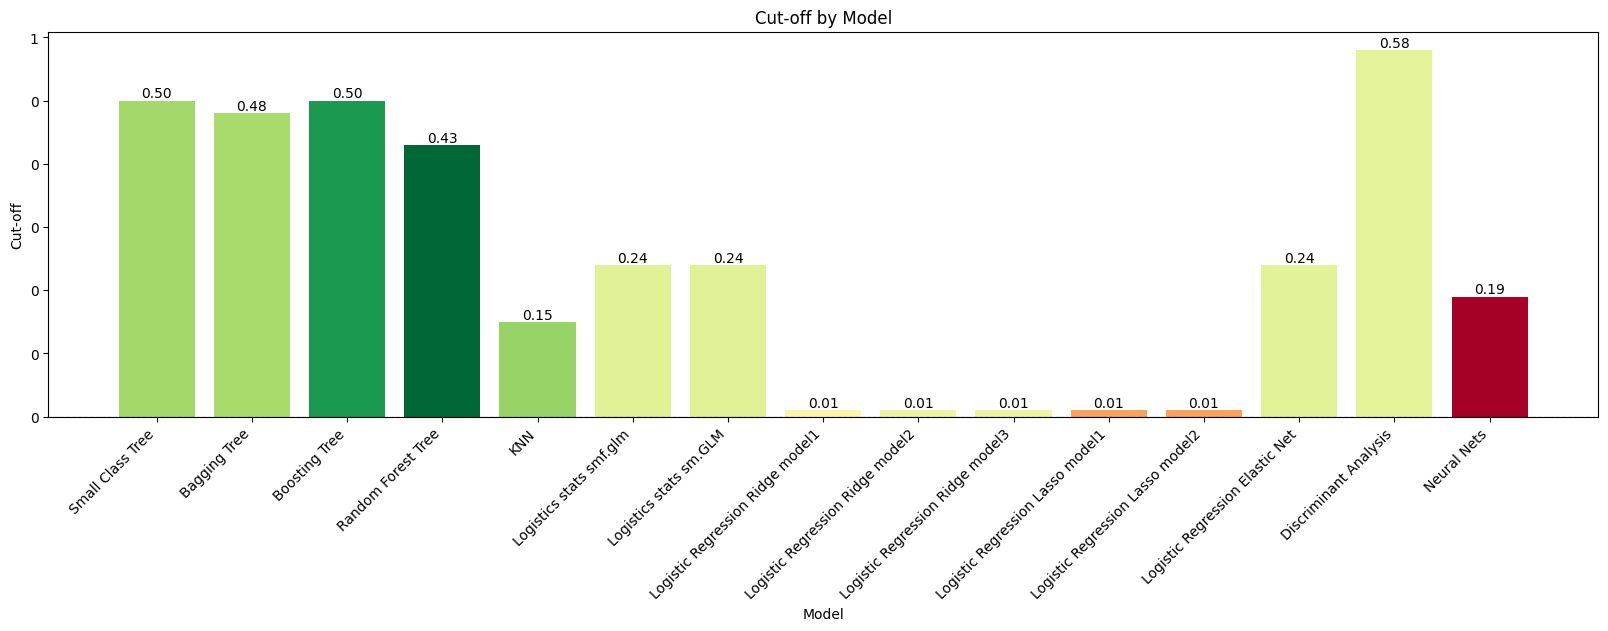

In [17]:
# Create the bar chart
fig, ax = plt.subplots(figsize=(20, 5))

# Ensure numeric conversion for 'Cutoff'
models['Cutoff'] = pd.to_numeric(models['Cutoff'], errors='coerce')

# Normalize Netprofit values for the colormap
norm = plt.Normalize(models['Netprofit'].min(), models['Netprofit'].max())
cmap = plt.cm.RdYlGn  # Red to Green colormap

# Map NetProfit values to colors
colors = [cmap(norm(val)) for val in models['Netprofit']]

# Plot bars
bars = ax.bar(models['Model'], models['Cutoff'], color=colors)

# Add annotations for each bar
for bar in bars:
    height = bar.get_height()
    y_offset = 5 if height >= 0 else -10  # Adjust spacing dynamically
    ax.annotate(
        f"{height:,.2f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, y_offset),
        textcoords="offset points",
        ha='center',
        va='center',
        fontsize=10,  # Adjust font size if needed
        color='black',
    )

# Set labels and title
ax.set_xlabel('Model')
ax.set_ylabel('Cut-off')
ax.set_title('Cut-off by Model')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')  # Add a horizontal line at 0

# Rotate x-axis labels for better visibility
ax.set_xticks(range(len(models['Model'])))
ax.set_xticklabels(models['Model'], rotation=45, ha='right')

# Format y-axis ticks
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

plt.show()

# Best Models

In [ ]:
# List of metrics to rank models
metrics = ['Precision', 'Recall', 'F1 Score', 'Specificity', 'Netprofit']

# Dictionary to store top 5 models for each metric
top_models = {}

# Loop through each metric and get top 5 models
for metric in metrics:
    top_models[metric] = models.sort_values(by=metric, ascending=False).head(5)

# Display results
for metric, top_df in top_models.items():
    print(f"\nTop 5 Models for {metric}:\n")

    # Format Netprofit with dollar sign and commas
    if metric == 'Netprofit':
        top_df[metric] = top_df[metric].apply(lambda x: f"${x:,.2f}")

    # Print the table with better formatting
    print(top_df[['Model', metric]].to_string(index=False))



Top 5 Models for Precision:

             Model  Precision
       Neural Nets   0.522695
               KNN   0.461046
     Boosting Tree   0.366538
Random Forest Tree   0.357343
      Bagging Tree   0.346693

Top 5 Models for Recall:

                           Model   Recall
Logistic Regression Ridge model3 0.928566
           Discriminant Analysis 0.920556
                    Bagging Tree 0.823573
                Small Class Tree 0.808831
Logistic Regression Ridge model1 0.733250

Top 5 Models for F1 Score:

                           Model  F1 Score
                    Bagging Tree  0.487969
                Small Class Tree  0.477184
                   Boosting Tree  0.474549
Logistic Regression Ridge model3  0.454563
           Discriminant Analysis  0.449450

Top 5 Models for Specificity:

                           Model  Specificity
         Logistics stats smf.glm          1.0
          Logistics stats sm.GLM          1.0
Logistic Regression Lasso model1          1.0
Logistic

# Recommendations

## For choosing the best model based on net profit

In [ ]:
# Focus only on 'Netprofit' metric
metrics = ['Netprofit']

# Dictionary to store top 5 models for each metric
top_models = {}

# Loop through each metric and get top 5 models
for metric in metrics:
    top_models[metric] = models.sort_values(by=metric, ascending=False).head(5)

# Display results
for metric, top_df in top_models.items():
    print(f"\nTop 5 Models for {metric}:\n")

    # Format Netprofit with dollar sign and commas
    if metric == 'Netprofit':
        top_df[metric] = top_df[metric].apply(lambda x: f"${x:,.2f}")

    # Print the table with better formatting
    print(top_df[['Model', metric]].to_string(index=False))



Top 5 Models for Netprofit:

             Model         Netprofit
Random Forest Tree $1,689,173,283.50
     Boosting Tree $1,513,240,958.35
               KNN $1,214,843,472.46
  Small Class Tree $1,186,554,830.80
      Bagging Tree $1,169,842,609.15


The Random Forest model is the best model if the focus is only on Net Profit.

## For choosing the best model based on recall

In [ ]:
# Focus only on 'Recall' metric
metrics = ['Recall']

# Dictionary to store top 5 models for each metric
top_models = {}

# Loop through each metric and get top 5 models
for metric in metrics:
    top_models[metric] = models.sort_values(by=metric, ascending=False).head(5)

# Display results
for metric, top_df in top_models.items():
    print(f"\nTop 5 Models for {metric}:\n")

    # Format Netprofit with dollar sign and commas
    if metric == 'Recall':
        top_df[metric] = top_df[metric].apply(lambda x: f"{x:,.4f}")

    # Print the table with better formatting
    print(top_df[['Model', metric]].to_string(index=False))



Top 5 Models for Recall:

                           Model Recall
Logistic Regression Ridge model3 0.9286
           Discriminant Analysis 0.9206
                    Bagging Tree 0.8236
                Small Class Tree 0.8088
Logistic Regression Ridge model1 0.7332


The Logistic Regression using Ridge (model 3 in that script) is the best model for choosing based on the recall score.

## For choosing the best model based on precision

In [ ]:
# Focus only on 'Precision' metric
metrics = ['Precision']

# Dictionary to store top 5 models for each metric
top_models = {}

# Loop through each metric and get top 5 models
for metric in metrics:
    top_models[metric] = models.sort_values(by=metric, ascending=False).head(5)

# Display results
for metric, top_df in top_models.items():
    print(f"\nTop 5 Models for {metric}:\n")

    # Format Netprofit with dollar sign and commas
    if metric == 'Precision':
        top_df[metric] = top_df[metric].apply(lambda x: f"{x:,.4f}")

    # Print the table with better formatting
    print(top_df[['Model', metric]].to_string(index=False))



Top 5 Models for Precision:

             Model Precision
       Neural Nets    0.5227
               KNN    0.4610
     Boosting Tree    0.3665
Random Forest Tree    0.3573
      Bagging Tree    0.3467


The Neural Net model is the best model if the focus is on Precision, however, this model yielded a negative net profit.

## For choosing the best model based on F1

In [ ]:
# Focus only on 'F1 Score' metric
metrics = ['F1 Score']

# Dictionary to store top 5 models for each metric
top_models = {}

# Loop through each metric and get top 5 models
for metric in metrics:
    top_models[metric] = models.sort_values(by=metric, ascending=False).head(5)

# Display results
for metric, top_df in top_models.items():
    print(f"\nTop 5 Models for {metric}:\n")

    # Format Netprofit with dollar sign and commas
    if metric == 'F1 Score':
        top_df[metric] = top_df[metric].apply(lambda x: f"{x:,.4f}")

    # Print the table with better formatting
    print(top_df[['Model', metric]].to_string(index=False))



Top 5 Models for F1 Score:

                           Model F1 Score
                    Bagging Tree   0.4880
                Small Class Tree   0.4772
                   Boosting Tree   0.4745
Logistic Regression Ridge model3   0.4546
           Discriminant Analysis   0.4495


The Bagging Tree model is the best model if the focus is on the F1 score.

# Final Recommendation

After comparing all the models, we recommend the Random Forest model as it yielded the highest net profit even though the other metrics did not rank as high. The F1 score was comparable to the top 5 models showing that this is a more balanced model.

The Logistic Regression using Ridge (model 3) and the Bagging Tree would be good alternatives as they rank high in both Recall and F1 Score.